# 05 · Random Forest and Naive Bayes

This notebook adds two models from the project proposal and compares them with the previous logistic-regression and decision-tree references on the **same validation rows**. It uses the same PaySim file, feature assumptions, preprocessing approach, seed and stratified 70/15/15 split as notebooks 03 and 04.

**Today's models**
- Gaussian Naive Bayes: a simple probabilistic classifier. Its Gaussian and conditional-independence assumptions may not fit these financial features or one-hot encoded categories.
- Random Forest: 20 trees, maximum depth 12 and minimum 50 training observations per leaf. To keep training practical, each tree draws a bootstrap sample of **10% of the full training partition with replacement**; training runs one tree at a time. These are initial settings, not a tuned optimum.

The earlier logistic and decision-tree pipelines are loaded from the project's trusted local checkpoints. Only open joblib files from trusted sources: loading them can execute code. If a checkpoint is missing or its recorded dataset, features, seed, split or package versions differ, rerun the earlier notebook in this environment before proceeding.

**Limitations:** The data is synthetic; a random transaction split does not test future periods or unseen accounts. Prior exploratory analysis summarized the complete dataset, so the reserved test set is not fully blinded to aggregate exploration. This notebook does not use the test partition for model fitting, scoring, or threshold selection. All model comparisons and chosen thresholds are exploratory validation results, not final test results.

**Run:** select the project `.venv` kernel in VS Code and choose **Run All**. Training can take several minutes.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits
import sys as _sys
_sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
from paydev import (SEED, FEATURES, NUMERIC, CATEGORICAL, SPLIT, EXPECTED_SHA256,
                    find_root, data_path, load_dataset, stratified_splits)

ROOT = find_root()
DATA_PATH = data_path(ROOT)
print("Dataset:", DATA_PATH.relative_to(ROOT).as_posix())
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Dataset: data/raw/PS_20174392719_1491204439457_log.csv
Python 3.15.2 | pandas 3.1.1 | NumPy 2.5.4 | scikit-learn 1.9.1


## 1. Reproduce the earlier split

Predictions are assumed to be made before the transaction is completed, with both pre-transaction balances available. Transaction IDs, post-transaction balances and `isFlaggedFraud` are excluded. Both the simulator clock and balances may encode synthetic artifacts; feature ablations are still needed.

In [2]:
df, actual_sha256 = load_dataset(ROOT)
print("Dataset SHA-256:", actual_sha256)
y = df["isFraud"].to_numpy(copy=True)
train_ids, val_ids, test_ids = stratified_splits(y, seed=SEED)
split_table = pd.DataFrame([{"partition": label, "transactions": len(ids), "fraud": int(y[ids].sum()),
                             "fraud_rate_percent": float(y[ids].mean() * 100)}
                            for label, ids in [("Train", train_ids), ("Validation", val_ids), ("Test (reserved)", test_ids)]]).set_index("partition")
display(split_table)

Dataset SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


,transactions,fraud,fraud_rate_percent
partition,,,
Train,4453834,5749,0.129080
Validation,954393,1232,0.129087
Test (reserved),954393,1232,0.129087


## 2. Load the earlier reference models

The metadata check verifies the dataset fingerprint, split description, seed, features and package versions recorded in each checkpoint. It does not prove the artifact's provenance or integrity; use only the files generated by this project and sources you trust.

In [3]:
reference_files = {"Logistic regression": "logistic_regression_baseline.joblib",
                   "Decision tree": "decision_tree_baseline.joblib"}
models = {}
for name, filename in reference_files.items():
    path = ROOT / "models" / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing {filename}. Rerun notebooks 03 and 04 to create trusted checkpoints.")
    checkpoint = joblib.load(path)
    expected = {"dataset_sha256": actual_sha256, "seed": SEED, "split": SPLIT,
                "features": FEATURES, "sklearn_version": sklearn.__version__,
                "numpy_version": np.__version__, "pandas_version": pd.__version__}
    mismatch = {k: (checkpoint.get(k), v) for k, v in expected.items() if checkpoint.get(k) != v}
    if mismatch:
        raise ValueError(f"Checkpoint {filename} is incompatible: {mismatch}. Retrain it in this environment.")
    models[name] = checkpoint["pipeline"]
    print(f"Loaded compatible reference: {name} ({filename})")
del checkpoint

Loaded compatible reference: Logistic regression (logistic_regression_baseline.joblib)
Loaded compatible reference: Decision tree (decision_tree_baseline.joblib)


## 3. Train the new models

Both pipelines learn the same standardization and one-hot encoding using only the training partition. Gaussian Naive Bayes is fitted on all training rows. The forest's eligible training pool is the same partition, but each tree draws 10% of its rows with replacement, as documented above. No resampling across partitions, hyperparameter search or class weighting is used.

One-hot values are not normally distributed, so Gaussian Naive Bayes is a simple baseline with an imperfect distributional assumption. Scores can be extreme and should not be assumed calibrated.

In [4]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("type", OneHotEncoder(handle_unknown="ignore", dtype=np.float32, sparse_output=False), CATEGORICAL),
], remainder="drop", sparse_threshold=0)
new_models = {
    "Gaussian Naive Bayes": Pipeline([("preprocess", clone(preprocess)), ("classifier", GaussianNB())]),
    "Random Forest": Pipeline([("preprocess", clone(preprocess)), ("classifier", RandomForestClassifier(
        n_estimators=20, max_depth=12, min_samples_leaf=50, bootstrap=True, max_samples=.10,
        n_jobs=1, random_state=SEED))]),
}
X_train = df.iloc[train_ids][FEATURES]
X_val = df.iloc[val_ids][FEATURES]
y_train, y_val = y[train_ids], y[val_ids]
fit_times = {}
for name, model in new_models.items():
    start = time.perf_counter()
    with threadpool_limits(limits=2):
        model.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - start
    models[name] = model
    print(f"{name}: trained in {fit_times[name]:.1f} seconds")
print(f"Forest draws {round(len(train_ids) * .10):,} rows with replacement per tree from {len(train_ids):,} training rows.")
print("Test rows remain reserved.")

Gaussian Naive Bayes: trained in 2.4 seconds
Random Forest: trained in 47.3 seconds
Forest draws 445,383 rows with replacement per tree from 4,453,834 training rows.
Test rows remain reserved.


## 4. Compare validation results

Average precision (AP) is the step-wise precision–recall summary and differs from trapezoidal PR-AUC. The 0.5 threshold is shown for reference. Each model's second threshold maximizes F1 on **this same validation set**, so the threshold-selected F1 is optimistically biased and should not be treated as test performance. The forest has restricted training settings and its comparison is not an optimized-model benchmark.

In [5]:
scores, curves, selected, rows = {}, {}, {}, []
def measure(y_true, score, threshold):
    pred = score >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": float(threshold), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "false_positives": int(fp), "false_negatives": int(fn), "alerts": int(fp + tp),
            "alert_rate_percent": 100 * (fp + tp) / len(y_true)}
for name, model in models.items():
    with threadpool_limits(limits=2):
        score = model.predict_proba(X_val)[:, 1]
    scores[name] = score
    precision, recall, thresholds = precision_recall_curve(y_val, score)
    denom = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], denom, out=np.zeros_like(thresholds), where=denom != 0)
    selected[name] = float(thresholds[int(np.argmax(f1))])
    curves[name] = (precision, recall)
    ap, roc = float(average_precision_score(y_val, score)), float(roc_auc_score(y_val, score))
    for label, threshold in [("Default 0.50", .5), ("F1 selected on validation", selected[name])]:
        rows.append({"model": name, "operating_point": label, "average_precision": ap, "ROC_AUC": roc,
                     **measure(y_val, score, threshold), "training_seconds": fit_times.get(name, np.nan)})
results = pd.DataFrame(rows).set_index(["model", "operating_point"])
display(results.round(4))
print(f"Validation fraud prevalence: {y_val.mean():.4%} across {len(y_val):,} rows.")
print("Training time is not repeated for loaded reference checkpoints.")

average_precision  ROC_AUC  \
model                operating_point                                         
Logistic regression  Default 0.50                          0.1781   0.9317   
                     F1 selected on validation             0.1781   0.9317   
Decision tree        Default 0.50                          0.6281   0.9821   
                     F1 selected on validation             0.6281   0.9821   
Gaussian Naive Bayes Default 0.50                          0.0030   0.7824   
                     F1 selected on validation             0.0030   0.7824   
Random Forest        Default 0.50                          0.6527   0.9930   
                     F1 selected on validation             0.6527   0.9930   

                                                threshold  precision  recall  \
model                operating_point                                           
Logistic regression  Default 0.50                  0.5000     0.9010  0.0739   
                     F1 selected on validation     0.0681     0.2423  0.2354   
Decision tree        Default 0.50                  0.5000     0.9057  0.4756   
                     F1 selected on validation     0.3784     0.7719  0.5576   
Gaussian Naive Bayes Default 0.50                  0.5000     0.0030  1.0000   
                     F1 selected on validation     1.0000     0.0030  1.0000   
Random Forest        Default 0.50                  0.5000     0.9856  0.3336   
                     F1 selected on validation     0.2677     0.8231  0.5097   

                                                    F1  false_positives  \
model                operating_point                                      
Logistic regression  Default 0.50               0.1365               10   
                     F1 selected on validation  0.2388              907   
Decision tree        Default 0.50               0.6237               61   
                     F1 selected on validation  0.6475              203   
Gaussian Naive Bayes Default 0.50               0.0059           414902   
                     F1 selected on validation  0.0059           414902   
Random Forest        Default 0.50               0.4985                6   
                     F1 selected on validation  0.6296              135   

                                                false_negatives  alerts  \
model                operating_point                                      
Logistic regression  Default 0.50                          1141     101   
                     F1 selected on validation              942    1197   
Decision tree        Default 0.50                           646     647   
                     F1 selected on validation              545     890   
Gaussian Naive Bayes Default 0.50                             0  416134   
                     F1 selected on validation                0  416134   
Random Forest        Default 0.50                           821     417   
                     F1 selected on validation              604     763   

                                                alert_rate_percent  \
model                operating_point                                 
Logistic regression  Default 0.50                           0.0106   
                     F1 selected on validation              0.1254   
Decision tree        Default 0.50                           0.0678   
                     F1 selected on validation              0.0933   
Gaussian Naive Bayes Default 0.50                          43.6020   
                     F1 selected on validation             43.6020   
Random Forest        Default 0.50                           0.0437   
                     F1 selected on validation              0.0799   

                                                training_seconds  
model                operating_point                              
Logistic regression  Default 0.50                            NaN  
                     F1 selected on validation               N

Validation fraud prevalence: 0.1291% across 954,393 rows.
Training time is not repeated for loaded reference checkpoints.


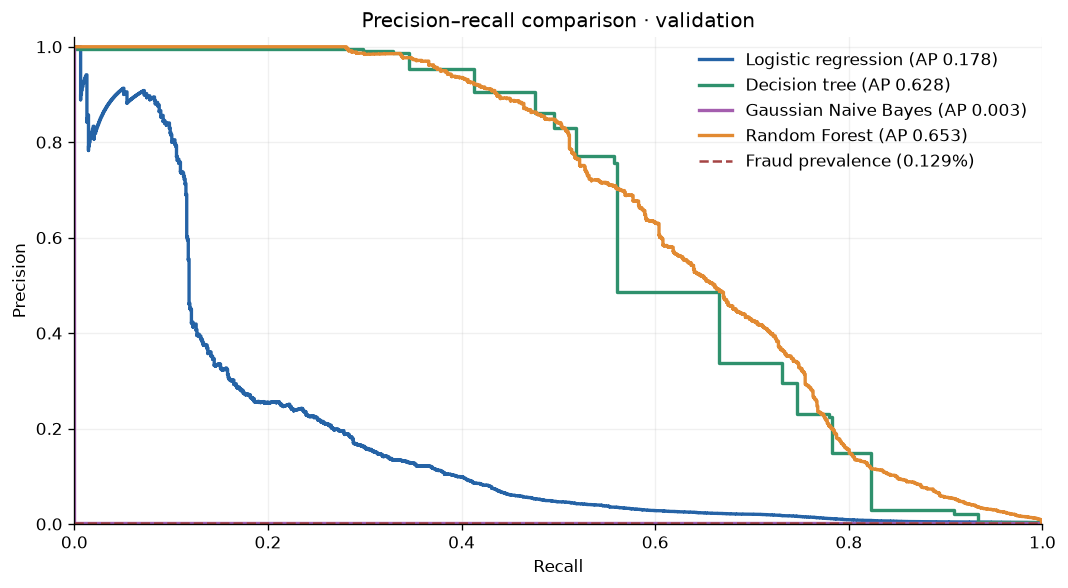

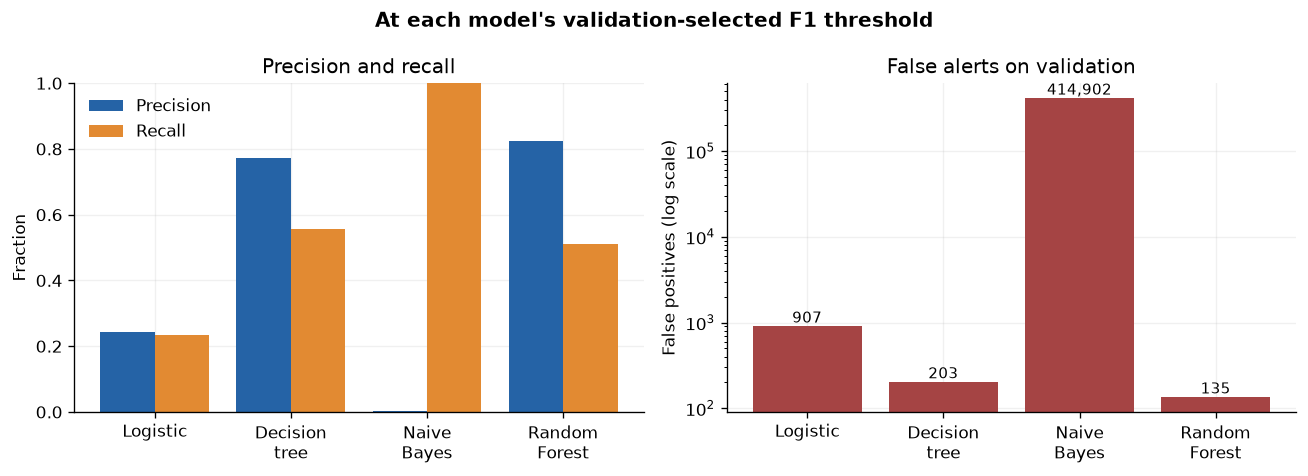

In [8]:
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2563a6", "#2f916d", "#a45eae", "#e28a32"]
for (name, (precision, recall)), color in zip(curves.items(), colors):
    ax.step(recall, precision, where="post", lw=2, color=color, label=f"{name} (AP {average_precision_score(y_val, scores[name]):.3f})")
ax.axhline(y_val.mean(), color="#a54444", ls="--", label=f"Fraud prevalence ({y_val.mean():.3%})")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision–recall comparison · validation")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

selected_rows = results.xs("F1 selected on validation", level="operating_point")
x = np.arange(len(selected_rows))
labels = ["Logistic", "Decision\ntree", "Naive\nBayes", "Random\nForest"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(x - .2, selected_rows["precision"], .4, color="#2563a6", label="Precision")
axes[0].bar(x + .2, selected_rows["recall"], .4, color="#e28a32", label="Recall")
axes[0].set(title="Precision and recall", ylabel="Fraction", ylim=(0, 1), xticks=x, xticklabels=labels)
axes[0].legend(frameon=False)
axes[1].bar(x, selected_rows["false_positives"], color="#a54444")
axes[1].set_yscale("log")
axes[1].set(title="False alerts on validation", ylabel="False positives (log scale)", xticks=x, xticklabels=labels)
for i, count in enumerate(selected_rows["false_positives"]):
    axes[1].annotate(f"{count:,}", (i, max(count, 1)), ha="center", va="bottom", fontsize=9)
fig.suptitle("At each model's validation-selected F1 threshold", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Save new checkpoints

These small checkpoints include preprocessing, the fitted model, selected threshold, data fingerprint, features, split, package versions and the forest's settings. Rerunning this cell replaces the two generated checkpoints. Model files must be trusted before loading.

In [7]:
paths = {"Gaussian Naive Bayes": "gaussian_naive_bayes.joblib", "Random Forest": "random_forest_baseline.joblib"}
for name, filename in paths.items():
    checkpoint = {"pipeline": models[name], "model_name": name, "threshold": selected[name],
                  "threshold_selection": "max F1 on validation", "features": FEATURES, "seed": SEED,
                  "split": SPLIT, "dataset_sha256": actual_sha256,
                  "validation_average_precision": float(average_precision_score(y_val, scores[name])),
                  "validation_roc_auc": float(roc_auc_score(y_val, scores[name])),
                  "python_version": sys.version.split()[0], "numpy_version": np.__version__,
                  "pandas_version": pd.__version__, "sklearn_version": sklearn.__version__}
    path = ROOT / "models" / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(checkpoint, path, compress=3)
    print(f"Saved {path.relative_to(ROOT).as_posix()} ({path.stat().st_size:,} bytes)")
print("No test rows were scored.")

Saved models/gaussian_naive_bayes.joblib (1,953 bytes)
Saved models/random_forest_baseline.joblib (94,305 bytes)
No test rows were scored.


## Next steps

The remaining proposed models are KNN, XGBoost and an ANN. Investigate training time and memory, evaluate improvements using training/validation data, and document the resources used. Feature, class-imbalance and temporal/account-aware analyses remain important before a final test evaluation.